# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data  
**Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)  
**Nama Mahasiswa:** Fandy Rohman Sifa Aminulloh  
**NIM:** 202310370311241  
**Username GitHub:** PanDiy2022

---

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.


## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [3]:
from pathlib import Path
import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go

# Mengarah ke root folder proyek
PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path.cwd().resolve()

path_raw = PROJECT_ROOT / "data" / "raw" / "playstore_com.whatsapp_2026-05-20_12-10-41.csv"
path_data = PROJECT_ROOT / "data" / "processed" / "dataset_bersih.parquet"

# Buat folder processed otomatis & generate parquet bersih via DuckDB (hemat RAM)
if not path_data.exists():
    path_data.parent.mkdir(parents=True, exist_ok=True)
    print("Membuat dataset_bersih.parquet dengan DuckDB (tunggu sekitar 5-15 detik)...")
    con = duckdb.connect()
    con.execute(f"""
        COPY (
            SELECT DISTINCT ON (reviewId)
                reviewId,
                userName,
                content,
                TRY_CAST(score AS INTEGER) AS score,
                COALESCE(TRY_CAST(thumbsUpCount AS INTEGER), 0) AS thumbsUpCount,
                TRY_CAST("at" AS TIMESTAMP) AS "at",
                replyContent,
                app_id
            FROM read_csv_auto('{path_raw.as_posix()}', all_varchar=true, ignore_errors=true)
            WHERE reviewId IS NOT NULL
              AND content IS NOT NULL
              AND TRIM(content) != ''
              AND TRY_CAST(score AS INTEGER) BETWEEN 1 AND 5
              AND TRY_CAST("at" AS TIMESTAMP) IS NOT NULL
              AND COALESCE(TRY_CAST(thumbsUpCount AS INTEGER), 0) >= 0
        ) TO '{path_data.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
    con.close()
    print("File dataset_bersih.parquet berhasil dibuat!\n")

# Muat dalam mode LazyFrame agar ringan
lf = pl.scan_parquet(path_data)
total_baris = lf.select(pl.len()).collect().item()
skema = lf.collect_schema()

print(f"Data Siap (Lazy Mode): {total_baris:,} baris x {len(skema)} kolom")
print("\nSkema Kolom & Tipe Data:")
for col, dtype in skema.items():
    print(f"- {col}: {dtype}")

lf.head(5).collect()

Membuat dataset_bersih.parquet dengan DuckDB (tunggu sekitar 5-15 detik)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

File dataset_bersih.parquet berhasil dibuat!

Data Siap (Lazy Mode): 6,186,903 baris x 8 kolom

Skema Kolom & Tipe Data:
- reviewId: String
- userName: String
- content: String
- score: Int32
- thumbsUpCount: Int32
- at: Datetime(time_unit='us', time_zone=None)
- replyContent: String
- app_id: String


reviewId,userName,content,score,thumbsUpCount,at,replyContent,app_id
str,str,str,i32,i32,datetime[μs],str,str
"""c242d1b6-a42f-4dc7-b7ec-94e2d0…","""surna wati""","""tolong buka spam wa, knp wa sa…",5,0,2025-11-11 11:25:30,null,"""com.whatsapp"""
"""2abe99c7-5954-4160-97e4-1ed99f…","""Farhan Putra""","""knapa ea WhatsApp slalu hilang…",3,0,2025-11-11 08:07:14,null,"""com.whatsapp"""
"""5f2260c2-0851-4b5b-80d6-c19882…","""amar hamzi""","""Saya mohon kepada pihak whatsa…",4,0,2025-11-10 17:47:32,null,"""com.whatsapp"""
"""99424faa-6f6d-4f40-8498-7af50d…","""Justin Rahman""","""Aplikasi bagus komunikasi""",4,0,2025-11-10 15:35:50,null,"""com.whatsapp"""
"""9fe21ed1-c3e2-4103-bb36-26bd29…","""Sonyaaa""","""balikin ini tiba-tiba nge buq …",3,0,2025-11-10 00:01:58,null,"""com.whatsapp"""


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`, atau DuckDB window functions)
untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

In [4]:
# Agregasi temporal bulanan menggunakan Polars group_by_dynamic & window functions
df_temporal = (
    lf.select(["at", "score", "thumbsUpCount"])
    .filter(pl.col("at").dt.year().is_between(2012, 2026))
    .sort("at")
    .group_by_dynamic("at", every="1mo")
    .agg([
        pl.len().alias("total_ulasan"),
        pl.col("score").mean().round(3).alias("rata_rating"),
        pl.col("thumbsUpCount").sum().alias("total_thumbs_up"),
    ])
    .with_columns([
        pl.col("total_ulasan").rolling_mean(window_size=3).round(1).alias("ma_3_bulan"),
        pl.col("rata_rating").rolling_mean(window_size=3).round(3).alias("rating_ma_3"),
        pl.col("total_ulasan").shift(1).alias("ulasan_bulan_lalu"),
        (
            (pl.col("total_ulasan") - pl.col("total_ulasan").shift(1))
            / pl.col("total_ulasan").shift(1) * 100
        ).round(2).alias("pertumbuhan_mom_pct"),
        pl.col("total_ulasan").cum_sum().alias("akumulasi_ulasan"),
    ])
    .collect()
)

print(f"Rentang waktu: {df_temporal['at'].min()} s.d. {df_temporal['at'].max()} ({len(df_temporal)} bulan)")
puncak = df_temporal.sort("total_ulasan", descending=True).row(0, named=True)
print(f"Bulan ulasan tertinggi: {str(puncak['at'])[:7]} ({puncak['total_ulasan']:,} ulasan, rating rata-rata {puncak['rata_rating']})")
df_temporal.tail(10)

Rentang waktu: 2019-05-01 00:00:00 s.d. 2026-05-01 00:00:00 (85 bulan)
Bulan ulasan tertinggi: 2019-06 (145,070 ulasan, rating rata-rata 4.312)


at,total_ulasan,rata_rating,total_thumbs_up,ma_3_bulan,rating_ma_3,ulasan_bulan_lalu,pertumbuhan_mom_pct,akumulasi_ulasan
datetime[μs],u32,f64,i32,f64,f64,u32,f64,u32
2025-08-01 00:00:00,24356,3.534,128888,30202.3,3.584,30471,1.4095e7,5884742
2025-09-01 00:00:00,30173,3.538,116330,28333.3,3.538,24356,23.88,5914915
2025-10-01 00:00:00,29465,3.622,119312,27998.0,3.565,30173,1.4234e7,5944380
2025-11-01 00:00:00,27993,3.517,162119,29210.3,3.559,29465,1.4577e7,5972373
2025-12-01 00:00:00,33360,3.758,145402,30272.7,3.632,27993,19.17,6005733
2026-01-01 00:00:00,44385,3.997,96711,35246.0,3.757,33360,33.05,6050118
2026-02-01 00:00:00,44896,4.139,109440,40880.3,3.965,44385,1.15,6095014
2026-03-01 00:00:00,40763,4.126,38810,43348.0,4.087,44896,9.5665e6,6135777
2026-04-01 00:00:00,30852,3.778,45526,38837.0,4.014,40763,1.0536e7,6166629


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:
- Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
- Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
- Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
- Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
- Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
- Visualisasi 6: Pola spasial atau korelasi multi-dimensi

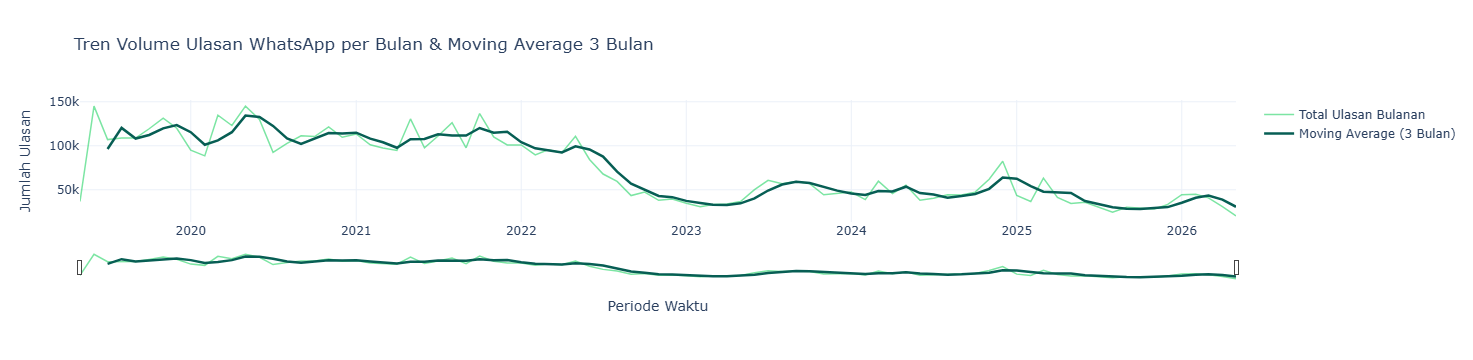

In [5]:
# Visualisasi 1: Tren Waktu Interaktif dengan Range Slider
fig1 = go.Figure()

fig1.add_trace(go.Scatter(
    x=df_temporal["at"],
    y=df_temporal["total_ulasan"],
    mode="lines",
    name="Total Ulasan Bulanan",
    line=dict(color="#25D366", width=1.5),
    opacity=0.6
))

fig1.add_trace(go.Scatter(
    x=df_temporal["at"],
    y=df_temporal["ma_3_bulan"],
    mode="lines",
    name="Moving Average (3 Bulan)",
    line=dict(color="#075E54", width=2.5)
))

fig1.update_layout(
    title="Tren Volume Ulasan WhatsApp per Bulan & Moving Average 3 Bulan",
    xaxis_title="Periode Waktu",
    yaxis_title="Jumlah Ulasan",
    hovermode="x unified",
    template="plotly_white"
)
fig1.update_xaxes(rangeslider_visible=True)
fig1.show()

shape: (5, 4)
┌───────┬─────────┬─────────────────┬───────────────┐
│ score ┆ jumlah  ┆ median_karakter ┆ rata_karakter │
│ ---   ┆ ---     ┆ ---             ┆ ---           │
│ i32   ┆ u32     ┆ f64             ┆ f64           │
╞═══════╪═════════╪═════════════════╪═══════════════╡
│ 1     ┆ 872484  ┆ 35.0            ┆ 60.0          │
│ 2     ┆ 264414  ┆ 34.0            ┆ 58.3          │
│ 3     ┆ 398587  ┆ 20.0            ┆ 44.0          │
│ 4     ┆ 584923  ┆ 12.0            ┆ 30.3          │
│ 5     ┆ 4066495 ┆ 9.0             ┆ 21.4          │
└───────┴─────────┴─────────────────┴───────────────┘


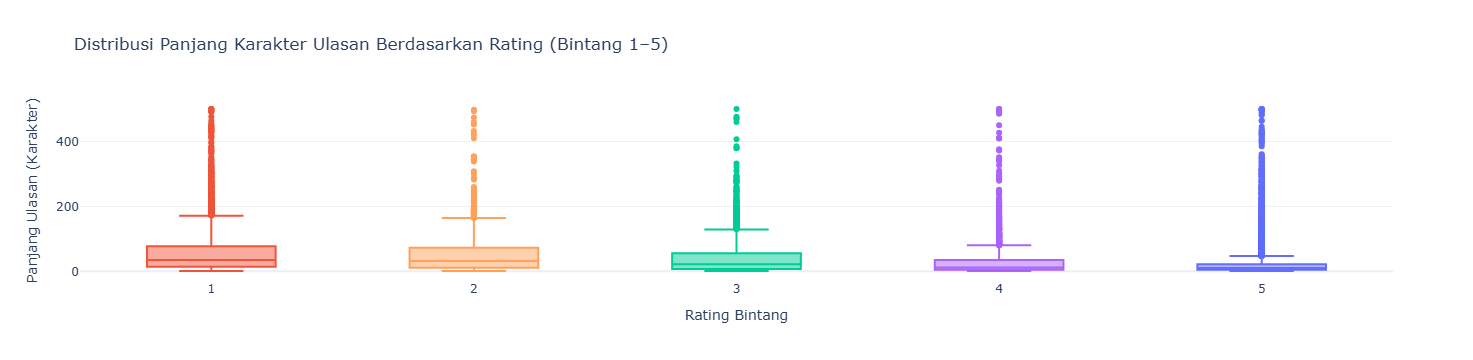

In [6]:
# Visualisasi 2: Distribusi Panjang Karakter Ulasan berdasarkan Skor Rating (Sampel 30.000 baris)
df_box = (
    lf.select([
        pl.col("score"),
        pl.col("content").str.len_chars().alias("panjang_karakter")
    ])
    .filter(pl.col("panjang_karakter") <= 500)  # Filter ekstrem agar box plot terbaca jelas
    .gather_every(200)  # Sampling sistematis ~30 ribu baris agar ringan
    .collect()
)

# Cetak ringkasan median panjang karakter per skor dari keseluruhan 6,18 juta data
ringkasan_panjang = (
    lf.group_by("score")
    .agg([
        pl.len().alias("jumlah"),
        pl.col("content").str.len_chars().median().alias("median_karakter"),
        pl.col("content").str.len_chars().mean().round(1).alias("rata_karakter"),
    ])
    .sort("score")
    .collect()
)
print(ringkasan_panjang)

fig2 = px.box(
    df_box.to_pandas(),
    x="score",
    y="panjang_karakter",
    color="score",
    title="Distribusi Panjang Karakter Ulasan Berdasarkan Rating (Bintang 1–5)",
    labels={"score": "Rating Bintang", "panjang_karakter": "Panjang Ulasan (Karakter)"},
    template="plotly_white"
)
fig2.update_layout(showlegend=False)
fig2.show()

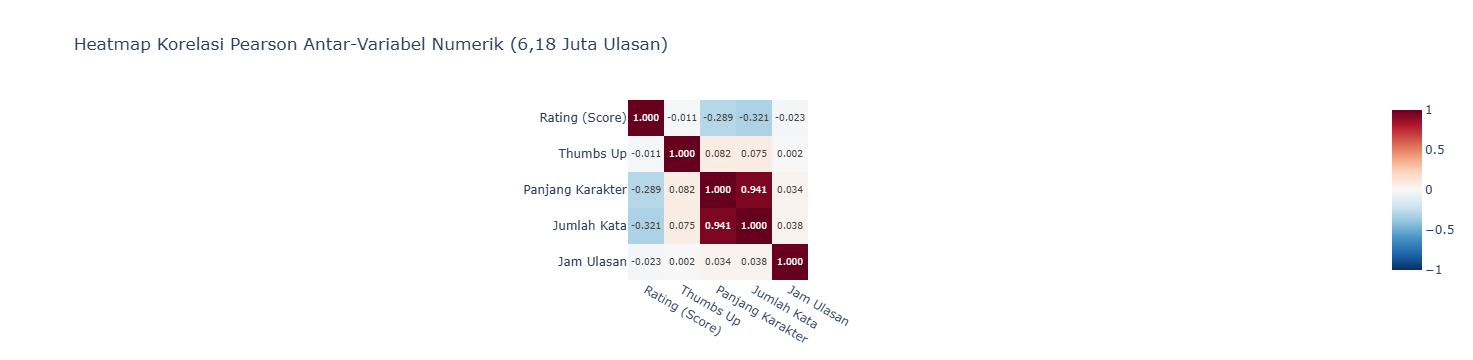

In [7]:
# Visualisasi 3: Matriks Korelasi Antar-Variabel Numerik
df_num = (
    lf.select([
        pl.col("score").cast(pl.Float64).alias("Rating (Score)"),
        pl.col("thumbsUpCount").cast(pl.Float64).alias("Thumbs Up"),
        pl.col("content").str.len_chars().cast(pl.Float64).alias("Panjang Karakter"),
        pl.col("content").str.split(" ").list.len().cast(pl.Float64).alias("Jumlah Kata"),
        pl.col("at").dt.hour().cast(pl.Float64).alias("Jam Ulasan"),
    ])
    .collect()
)

kolom_num = df_num.columns
corr_matrix = df_num.corr().to_numpy()

fig3 = px.imshow(
    corr_matrix,
    x=kolom_num,
    y=kolom_num,
    text_auto=".3f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Heatmap Korelasi Pearson Antar-Variabel Numerik (6,18 Juta Ulasan)",
    template="plotly_white"
)
fig3.show()

shape: (7, 4)
┌───────┬───────────────────┬───────────────┬────────────┐
│ score ┆ status_balasan    ┆ jumlah_ulasan ┆ persentase │
│ ---   ┆ ---               ┆ ---           ┆ ---        │
│ i32   ┆ str               ┆ u32           ┆ f64        │
╞═══════╪═══════════════════╪═══════════════╪════════════╡
│ 1     ┆ Dibalas Developer ┆ 1             ┆ 0.0        │
│ 1     ┆ Tidak Dibalas     ┆ 872483        ┆ 14.1       │
│ 2     ┆ Dibalas Developer ┆ 1             ┆ 0.0        │
│ 2     ┆ Tidak Dibalas     ┆ 264413        ┆ 4.27       │
│ 3     ┆ Tidak Dibalas     ┆ 398587        ┆ 6.44       │
│ 4     ┆ Tidak Dibalas     ┆ 584923        ┆ 9.45       │
│ 5     ┆ Tidak Dibalas     ┆ 4066495       ┆ 65.73      │
└───────┴───────────────────┴───────────────┴────────────┘


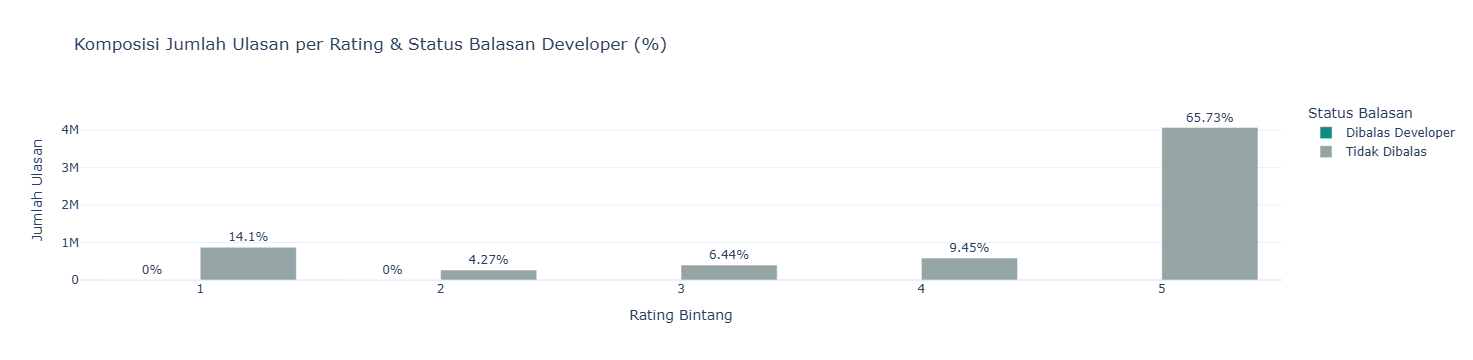

In [8]:
# Visualisasi 4: Komposisi Rating Bintang & Status Balasan Pengembang
df_komposisi = (
    lf.with_columns(
        pl.when(pl.col("replyContent").is_not_null() & (pl.col("replyContent").str.strip_chars() != ""))
        .then(pl.lit("Dibalas Developer"))
        .otherwise(pl.lit("Tidak Dibalas"))
        .alias("status_balasan")
    )
    .group_by(["score", "status_balasan"])
    .agg(pl.len().alias("jumlah_ulasan"))
    .sort(["score", "status_balasan"])
    .collect()
)

total_semua = df_komposisi["jumlah_ulasan"].sum()
df_komposisi = df_komposisi.with_columns(
    (pl.col("jumlah_ulasan") / total_semua * 100).round(2).alias("persentase")
)
print(df_komposisi)

fig4 = px.bar(
    df_komposisi.to_pandas(),
    x="score",
    y="jumlah_ulasan",
    color="status_balasan",
    barmode="group",
    text="persentase",
    title="Komposisi Jumlah Ulasan per Rating & Status Balasan Developer (%)",
    labels={"score": "Rating Bintang", "jumlah_ulasan": "Jumlah Ulasan", "status_balasan": "Status Balasan"},
    color_discrete_map={"Dibalas Developer": "#128C7E", "Tidak Dibalas": "#95A5A6"},
    template="plotly_white"
)
fig4.update_traces(texttemplate="%{text}%", textposition="outside")
fig4.show()

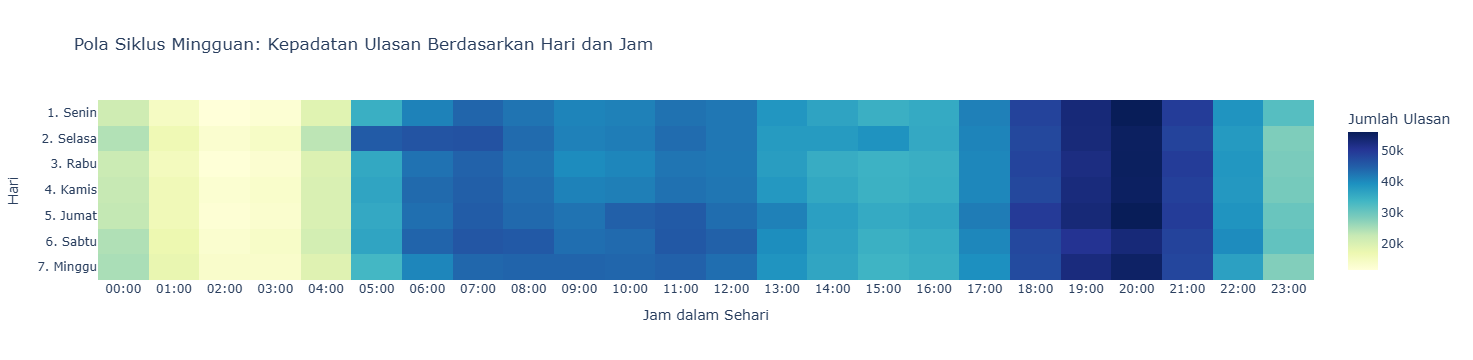

In [9]:
# Visualisasi 5: Siklus Aktivitas Ulasan Berdasarkan Hari & Jam
nama_hari = {1: "1. Senin", 2: "2. Selasa", 3: "3. Rabu", 4: "4. Kamis", 5: "5. Jumat", 6: "6. Sabtu", 7: "7. Minggu"}

df_siklus = (
    lf.select([
        pl.col("at").dt.weekday().alias("hari_angka"),
        pl.col("at").dt.hour().alias("jam")
    ])
    .group_by(["hari_angka", "jam"])
    .agg(pl.len().alias("jumlah_ulasan"))
    .sort(["hari_angka", "jam"])
    .collect()
    .with_columns(
        pl.col("hari_angka").replace_strict(nama_hari).alias("hari")
    )
)

pivot_siklus = df_siklus.pivot(values="jumlah_ulasan", index="hari", on="jam").sort("hari")
z_vals = pivot_siklus.drop("hari").to_numpy()
x_jam = [f"{int(c):02d}:00" for c in pivot_siklus.drop("hari").columns]
y_hari = pivot_siklus["hari"].to_list()

fig5 = px.imshow(
    z_vals,
    x=x_jam,
    y=y_hari,
    color_continuous_scale="YlGnBu",
    aspect="auto",
    title="Pola Siklus Mingguan: Kepadatan Ulasan Berdasarkan Hari dan Jam",
    labels={"x": "Jam dalam Sehari", "y": "Hari", "color": "Jumlah Ulasan"},
    template="plotly_white"
)
fig5.show()

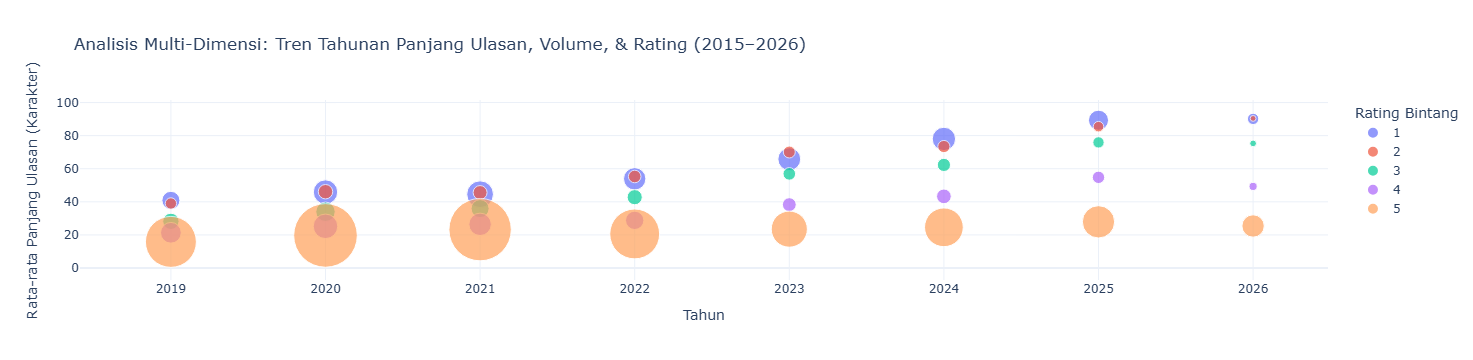

In [10]:
# Visualisasi 6: Analisis Multi-Dimensi (Evolusi Tahunan per Rating, Panjang Teks, & Thumbs Up)
df_multi = (
    lf.with_columns([
        pl.col("at").dt.year().alias("tahun"),
        pl.col("content").str.len_chars().alias("panjang_karakter")
    ])
    .filter(pl.col("tahun").is_between(2015, 2026))
    .group_by(["tahun", "score"])
    .agg([
        pl.len().alias("jumlah_ulasan"),
        pl.col("panjang_karakter").mean().round(1).alias("rata_panjang_karakter"),
        pl.col("thumbsUpCount").mean().round(2).alias("rata_thumbs_up"),
    ])
    .sort(["tahun", "score"])
    .collect()
)

fig6 = px.scatter(
    df_multi.to_pandas(),
    x="tahun",
    y="rata_panjang_karakter",
    size="jumlah_ulasan",
    color=df_multi["score"].cast(pl.Utf8).to_list(),
    hover_data=["jumlah_ulasan", "rata_thumbs_up"],
    size_max=45,
    title="Analisis Multi-Dimensi: Tren Tahunan Panjang Ulasan, Volume, & Rating (2015–2026)",
    labels={
        "tahun": "Tahun",
        "rata_panjang_karakter": "Rata-rata Panjang Ulasan (Karakter)",
        "color": "Rating Bintang",
        "jumlah_ulasan": "Total Ulasan",
        "rata_thumbs_up": "Rata-rata Thumbs Up"
    },
    template="plotly_white"
)
fig6.show()

## Bagian 4: Rumusan 5 Insight Analitik Utama

1. **Insight 1 (Tren Waktu & Musiman):**
   Volume ulasan bulanan WhatsApp berada pada fase puncak historis sepanjang pertengahan 2019 hingga akhir 2021 dengan rata-rata bergerak (*Moving Average* 3 bulan) stabil di kisaran **100.000–135.000 ulasan/bulan** (puncak tertinggi mendekati 145.000 ulasan pada pertengahan 2020). Memasuki pertengahan 2022, terjadi penurunan struktural ke level stabil baru sekitar **35.000–60.000 ulasan/bulan** pada periode 2023–2026, dengan lonjakan musiman menonjol pada akhir 2024 (~80.000 ulasan). Secara siklus mingguan dan harian, aktivitas pengiriman ulasan mengikuti ritme sirkadian yang seragam setiap hari: titik terendah terjadi pada jam istirahat dini hari (**01:00–03:00**, di bawah 20.000 ulasan/slot), mulai meningkat tajam pada pukul **05:00–07:00**, dan mencapai kepadatan tertinggi pada jam santai malam hari pukul **18:00–21:00** dengan puncak absolut pada pukul **20:00** (>50.000 ulasan per slot jam).

2. **Insight 2 (Distribusi & Anomali):**
   Distribusi rating menunjukkan ketimpangan ekstrem berbentuk huruf **J** (*J-shaped polarization*): **Rating 5 mendominasi sebesar 65,73%** (4.066.495 ulasan), diikuti oleh **Rating 1 sebesar 14,10%** (872.484 ulasan) yang jumlahnya melampaui gabungan Rating 2 (4,27%) dan Rating 3 (6,44%), serta Rating 4 sebesar 9,45% (584.923 ulasan). Pada distribusi panjang teks, ulasan berskor rendah memiliki sebaran jauh lebih lebar dan miring ke kanan (*right-skewed*) dengan banyak *outlier* hingga >500 karakter: median panjang ulasan **Rating 1 (35,0 karakter; rata-rata 60,0)** dan **Rating 2 (34,0 karakter; rata-rata 58,3)** hampir **4 kali lebih panjang** dibandingkan **Rating 5 (median 9,0 karakter; rata-rata 21,4)** yang umumnya hanya berupa pujian singkat seperti *"bagus"* atau *"mantap"*.

3. **Insight 3 (Korelasi Kunci):**
   Matriks korelasi Pearson pada 6,18 juta ulasan membuktikan adanya hubungan negatif yang konsisten antara **Rating (`score`) dengan Jumlah Kata ($r = -0,321$)** maupun **Panjang Karakter ($r = -0,289$)**, mengonfirmasi secara kuantitatif bahwa semakin rendah tingkat kepuasan pengguna, semakin panjang dan rinci teks ulasan yang ditulis. Variabel `Panjang Karakter` dan `Jumlah Kata` berkorelasi sangat kuat ($r = 0,941$), sedangkan `Thumbs Up` memiliki korelasi positif lemah terhadap panjang ulasan ($r = 0,082$), menandakan ulasan keluhan atau deskripsi yang lebih detail cenderung lebih banyak mendapat dukungan (*helpful votes*) dari pengguna lain. Sebaliknya, `Jam Ulasan` memiliki korelasi mendekati nol terhadap `Rating` ($r = -0,023$), sehingga waktu pengiriman ulasan tidak memengaruhi bias penilaian.

4. **Insight 4 (Perilaku Kategori / Segmen):**
   Analisis komposisi dan evolusi multi-dimensi (2019–2026) mengungkap dua temuan perilaku krusial. Pertama, tingkat respons pengembang (*Developer Reply Rate*) tercatat praktis **0%** (hanya **2 ulasan** yang dibalas dari total 6.186.903 ulasan, masing-masing 1 pada Rating 1 dan 1 pada Rating 2), menunjukkan tidak adanya interaksi balasan langsung pada kanal ulasan Play Store Indonesia. Kedua, tren tahunan memperlihatkan pergeseran kompleksitas keluhan: rata-rata panjang ulasan untuk **Rating 1 dan Rating 2 meningkat lebih dari dua kali lipat** dari kisaran **40–47 karakter** pada 2019–2021 menjadi **85–90 karakter** pada 2025–2026, sementara panjang ulasan Rating 5 tetap datar di kisaran 20–28 karakter. Hal ini menandakan keluhan pengguna di tahun-tahun terakhir semakin spesifik (seperti kendala pemblokiran akun/spam, *bug* pembaruan, dan hilangnya riwayat *chat*).

5. **Insight 5 (Rekomendasi Praktis):**
   - **Prioritas Pemantauan Pasca-Rilis pada Jam Puncak:** Tim teknis dan *product operations* perlu memfokuskan pemantauan *real-time* lonjakan ulasan negatif pada rentang pukul **18:00–21:00** (terutama pukul 20:00) setiap kali pembaruan aplikasi digulirkan, karena mayoritas umpan balik pengguna terkonsentrasi pada jendela waktu tersebut.
   - **Otomatisasi Triase Keluhan Berbasis Panjang Teks & Rating:** Karena ulasan Rating 1–2 memiliki panjang teks rata-rata 60–90 karakter dan memuat detail masalah teknis yang tinggi, sistem analitik NLP (*topic modeling* / klasifikasi sentimen) sebaiknya diprioritaskan pada segmen ulasan bintang 1–2 dengan panjang >35 karakter serta *thumbs up* tinggi untuk mendeteksi *bug* kritis lebih cepat.
   - **Implementasi Balasan Otomatis Terarah (*Templated Support Reply*):** Mengingat 14,10% (872 ribu+) ulasan adalah bintang 1 dengan tingkat balasan 0%, penyediaan balasan otomatis yang mengarahkan pengguna ke pusat bantuan resmi (khususnya untuk isu pemulihan akun/spam) dapat meningkatkan persepsi dukungan layanan secara signifikan.